In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as plt_sns

plt.rcParams["font.family"] = "DejaVu Sans"
plt_sns.set_theme(style="whitegrid")

print("Current folder:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current folder:
C:\Users\Admin

Files and folders here:
['.anaconda', '.cache', '.conda', '.condarc', '.continuum', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.local', '.streamlit', '.virtual_documents', '.vscode', '.vscode-shared', '3D Objects', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'dataset_preparation.ipynb', 'Documents', 'Downloads', 'Favorites', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{01d4e72b-c363-11f1-8f0d-afb2342b14dc}.TM.blf', 'NTUSER.DAT{01d4e72b-c363-11f1-8f0d-afb2342b14dc}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{01d4e72b-c363-11f1-8f0d-afb2342b14dc}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'PrintHood', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'Untitled.ipynb', 'Untitled1.ipynb', 'Videos']


In [5]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\skin-ga-cnn-v2\skin-ga-cnn\data\HAM10000_metadata.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMNS:")
print(df.columns.tolist())

Dataset loaded successfully!
Rows: 10015
Columns: 7

COLUMNS:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


In [6]:
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  str    
 1   image_id      10015 non-null  str    
 2   dx            10015 non-null  str    
 3   dx_type       10015 non-null  str    
 4   age           9958 non-null   float64
 5   sex           10015 non-null  str    
 6   localization  10015 non-null  str    
dtypes: float64(1), str(6)
memory usage: 990.6 KB


Missing values per column:
age    57
dtype: int64


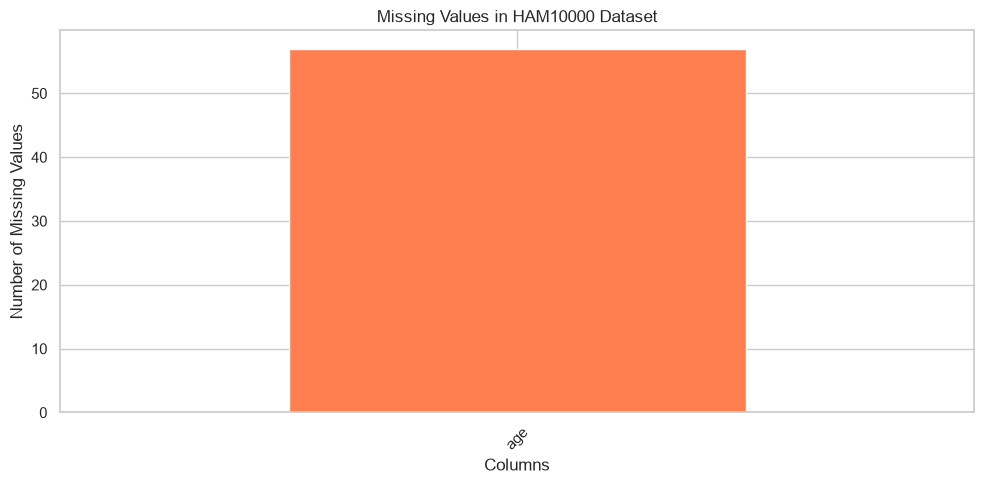

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values per column:")
print(missing if not missing.empty else "No missing values found!")

if not missing.empty:
    plt.figure(figsize=(10, 5))
    missing.plot(kind="bar", color="coral")
    plt.title("Missing Values in HAM10000 Dataset")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Target categories (Diagnosis Classes):
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


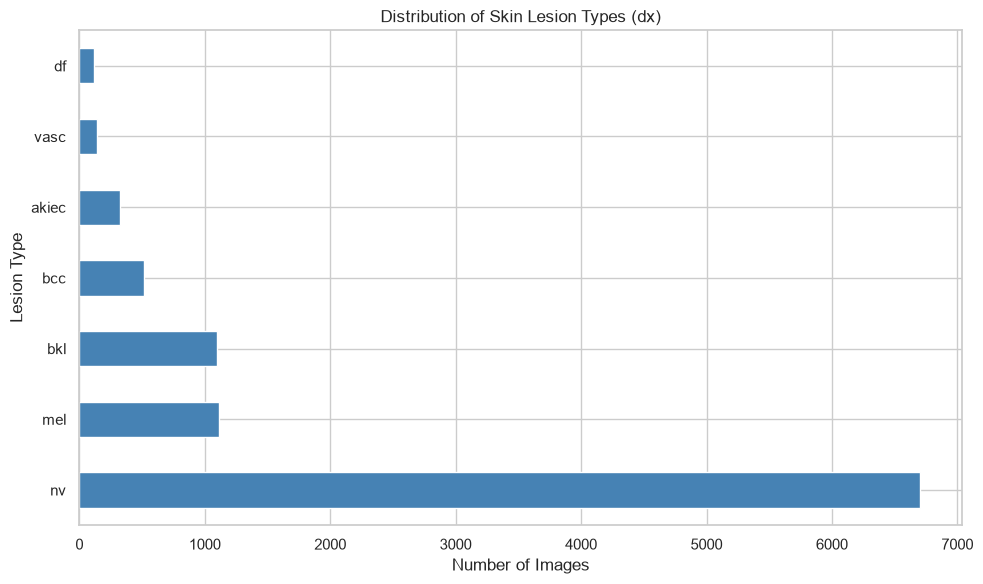

In [9]:
print("Target categories (Diagnosis Classes):")
print(df["dx"].value_counts())

plt.figure(figsize=(10, 6))
top_dx = df["dx"].value_counts()
top_dx.plot(kind="barh", color="steelblue")

plt.title("Distribution of Skin Lesion Types (dx)")
plt.xlabel("Number of Images")
plt.ylabel("Lesion Type")
plt.tight_layout()
plt.show()

Summary Statistics for Age:


,age
count,9958.00
mean,51.86
std,16.97
min,0.00
25%,40.00
50%,50.00
75%,65.00
max,85.00


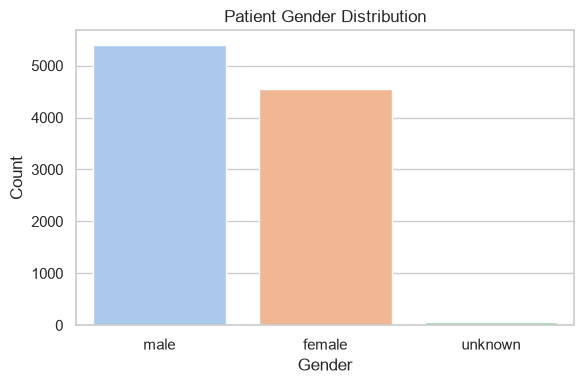

In [11]:
print("Summary Statistics for Age:")
display(df[["age"]].describe().round(2))

plt.figure(figsize=(6, 4))

plt_sns.countplot(
    data=df, 
    x="sex", 
    hue="sex", 
    order=df["sex"].value_counts().index, 
    palette="pastel",
    legend=False
)

plt.title("Patient Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

df_clean = df.dropna(subset=['age']).copy()

y = df_clean['age']
X_categorical = df_clean[['dx', 'sex', 'localization']]

X = pd.get_dummies(X_categorical, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("--- LINEAR REGRESSION TEST METRICS ---")
print(f"R-squared Score: {r2:.4f} (How well the features explain age variance)")
print(f"Mean Absolute Error: {mae:.2f} years (Average prediction error)\n")

print("--- THE LINEAR REGRESSION FORMULA FACTORS ---")
print(f"Base Age (Intercept / b): {model.intercept_:.2f} years\n")

coefficients = pd.DataFrame({
    'Feature': X.columns, 
    'Impact on Age (Years)': model.coef_
})

print("Top 5 features associated with OLDER patients:")
display(coefficients.sort_values(by='Impact on Age (Years)', ascending=False).head())

--- LINEAR REGRESSION TEST METRICS ---
R-squared Score: 0.2567 (How well the features explain age variance)
Mean Absolute Error: 11.57 years (Average prediction error)

--- THE LINEAR REGRESSION FORMULA FACTORS ---
Base Age (Intercept / b): 62.99 years

Top 5 features associated with OLDER patients:


,Feature,Impact on Age (Years)
6,sex_male,4.433575
11,localization_ear,2.297052
19,localization_trunk,1.640535
14,localization_genital,1.226904
21,localization_upper extremity,1.097771
